Task 1

Data Understanding and Visualization

In [ ]:
from google.colab import files
uploaded = files.upload()
zip_path = list(uploaded.keys())[0]
print(f"Uploaded file: {zip_path}")

Saving FruitinAmazon.zip to FruitinAmazon.zip
Uploaded file: FruitinAmazon.zip


In [ ]:
import zipfile
import os
zip_path = 'FruitinAmazon.zip'
extract_to = 'dataset_extracted'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to)
print("Folders found:", os.listdir(extract_to))

train_dir = os.path.join(extract_to, 'train')

Folders found: ['FruitinAmazon']


Get the list of class directories from the train folder.

In [ ]:
import os
print("Items in extraction folder:", os.listdir('dataset_extracted'))

Items in extraction folder: ['FruitinAmazon']


Select one image randomly from each class.

In [ ]:
import os
base_path = 'dataset_extracted/FruitinAmazon'

if os.path.exists(os.path.join(base_path, 'train')):
    train_dir = os.path.join(base_path, 'train')
else:
    train_dir = base_path
classes = [d for d in os.listdir(train_dir) if os.path.isdir(os.path.join(train_dir, d))]
print(f"Detected Classes: {classes}")

Detected Classes: ['graviola', 'guarana', 'acai', 'tucuma', 'pupunha', 'cupuacu']


Select one image randomly from each class

In [ ]:
import random

random_images = []

for cls in classes:
    class_path = os.path.join(train_dir, cls)
    all_images = [f for f in os.listdir(class_path) if os.path.isfile(os.path.join(class_path, f))]
    random_choice = random.choice(all_images)
    random_images.append(os.path.join(class_path, random_choice))
print(f"Successfully selected {len(random_images)} random images.")

Successfully selected 6 random images.


Display the images in a grid format (Two Rows)

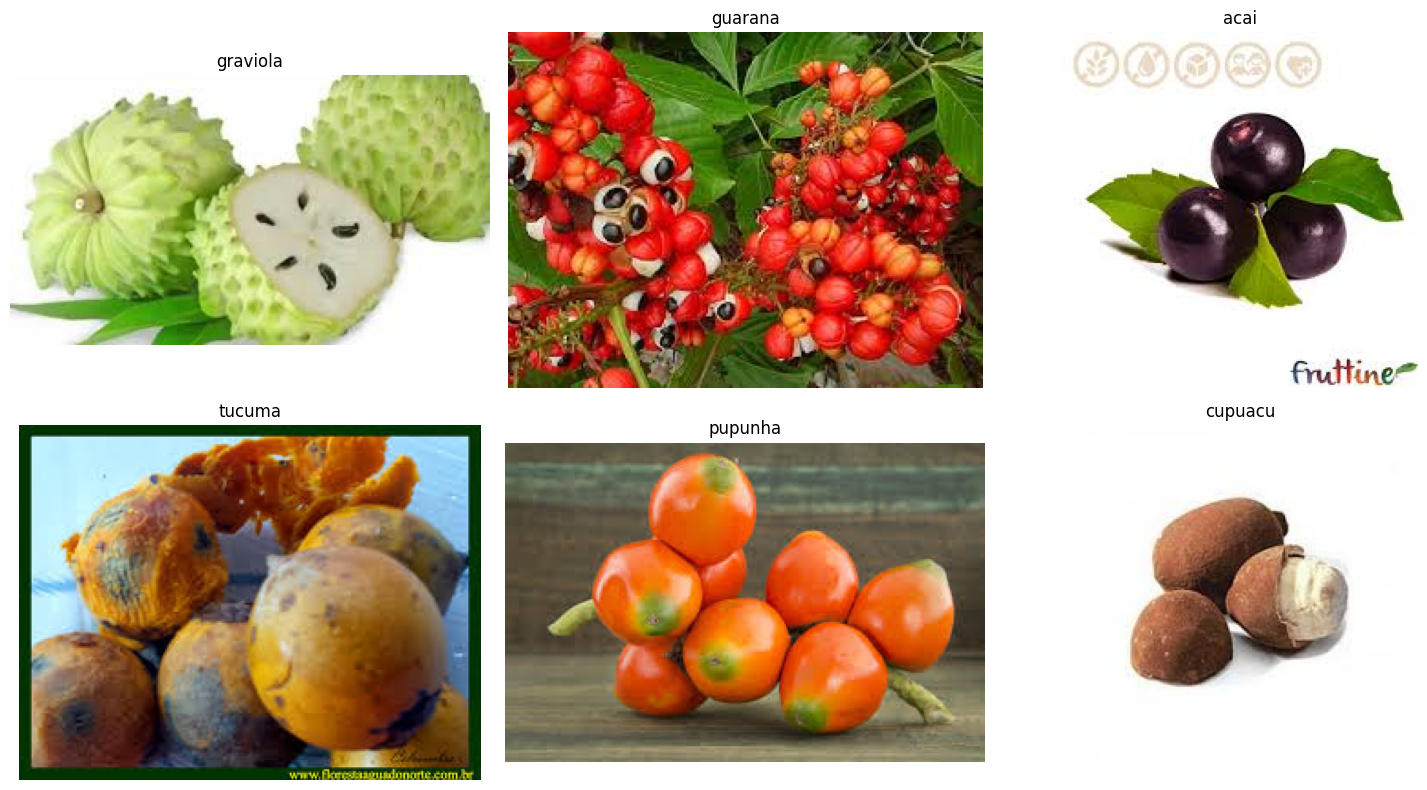

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import math

num_classes = len(classes)
cols = math.ceil(num_classes / 2)
plt.figure(figsize=(15, 8))
for i, img_path in enumerate(random_images):
    plt.subplot(2, cols, i + 1)
    img = Image.open(img_path)
    plt.imshow(img)
    plt.title(classes[i])
    plt.axis('off')
plt.tight_layout()
plt.show()

Check for Corrupted Image:

In [ ]:
import os
from PIL import Image
corrupted_images = []

for class_name in os.listdir(train_dir):
    class_path = os.path.join(train_dir, class_name)

    if os.path.isdir(class_path):
        for image_name in os.listdir(class_path):
            image_path = os.path.join(class_path, image_name)

            try:
                with Image.open(image_path) as img:
                    img.verify()
            except (IOError, SyntaxError):
                if os.path.exists(image_path):
                    os.remove(image_path)
                print(f"Removed corrupted image: {image_path}")
                corrupted_images.append(image_path)
if not corrupted_images:
    print("No Corrupted Images Found.")

No Corrupted Images Found.


Task 2: Loading and Preprocessing Image Data in keras:

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# This converts pixel values from 0-255 to 0-1
datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)

train_generator = datagen.flow_from_directory(
    train_dir,
    target_size=(150, 150),
    batch_size=16,
    class_mode='categorical',
    subset='training'
)

validation_generator = datagen.flow_from_directory(
    train_dir,
    target_size=(150, 150),
    batch_size=16,
    class_mode='categorical',
    subset='validation'
)

Found 72 images belonging to 6 classes.
Found 18 images belonging to 6 classes.


Task 3 - Implement a CNN

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

# Define the number of classes based on your folder structure
num_classes = len(classes)

#build the Model
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(150, 150, 3)),
    MaxPooling2D(2, 2),

    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),
    Flatten(),

    #takes flatten value, analyzes what could it be
    Dense(64, activation='relu'),
    Dense(128, activation='relu'),

    Dense(num_classes, activation='softmax')
])
model.compile(
    optimizer='adam', #adjust weight
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 41472)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     2,654,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,673,510 (10.20 MB)

 Trainable params: 2,673,510 (10.20 MB)

 Non-trainable params: 0 (0.00 B)

Task 4: Compile the Model

In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)
checkpoint = ModelCheckpoint(
    'best_fruit_model.h5',
    monitor='val_accuracy',
    save_best_only=True,
    mode='max'
)

In [ ]:
history = model.fit(
    train_generator,
    epochs=250,
    batch_size=16,
    validation_data=validation_generator,
    callbacks=[early_stopping, checkpoint],
    verbose=1
)

Epoch 1/250
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 429ms/step - accuracy: 1.0000 - loss: 0.1032

5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 512ms/step - accuracy: 1.0000 - loss: 0.0870 - val_accuracy: 0.6667 - val_loss: 1.2513
Epoch 2/250
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 385ms/step - accuracy: 1.0000 - loss: 0.0515 - val_accuracy: 0.6111 - val_loss: 1.1445
Epoch 3/250
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 430ms/step - accuracy: 1.0000 - loss: 0.0353 - val_accuracy: 0.5556 - val_loss: 1.1212
Epoch 4/250
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 670ms/step - accuracy: 1.0000 - loss: 0.0174 - val_accuracy: 0.6667 - val_loss: 1.5000
Epoch 5/250
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 497ms/step - accuracy: 1.0000 - loss: 0.0115 - val_accuracy: 0.5556 - val_loss: 1.5419
Epoch 6/250
5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 437ms/step - accuracy: 0.9861 - loss: 0.0353 - val_accuracy: 0.5000 - val_loss: 1.6210
Epoch 7/250
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 393ms/step - accuracy: 0.9861 - loss: 0.0659 - val_accuracy: 0.5556 - val_loss: 1.5829
Epoch 8/250
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 387ms/step - accuracy: 0.9444 - loss: 0.0933 - val_accuracy: 0.5000 - val_loss: 1.7

5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 602ms/step - accuracy: 0.9722 - loss: 0.0760 - val_accuracy: 0.7222 - val_loss: 1.3589
Epoch 11/250
5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 388ms/step - accuracy: 1.0000 - loss: 0.0441 - val_accuracy: 0.6111 - val_loss: 1.6976
Epoch 12/250
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 386ms/step - accuracy: 1.0000 - loss: 0.0085 - val_accuracy: 0.5000 - val_loss: 1.9438
Epoch 13/250
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 386ms/step - accuracy: 1.0000 - loss: 0.0123 - val_accuracy: 0.5556 - val_loss: 1.7023


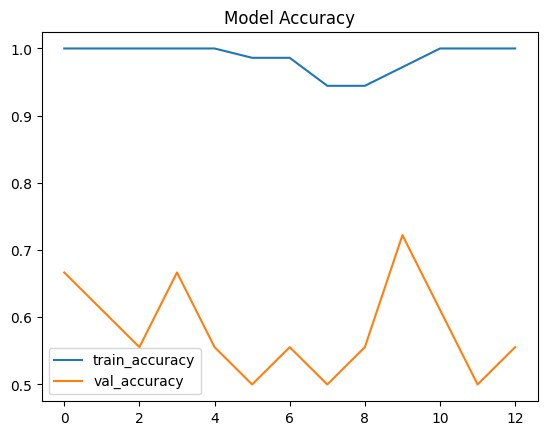

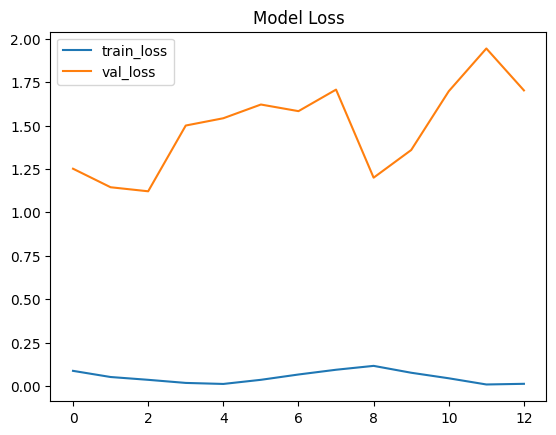

In [ ]:
import matplotlib.pyplot as plt

#model accuracy
plt.plot(history.history['accuracy'], label='train_accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.title('Model Accuracy')
plt.legend()
plt.show()

#model loss
plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.title('Model Loss')
plt.legend()
plt.show()

Task 5: Evaluate the Model

In [ ]:
test_loss, test_acc = model.evaluate(validation_generator)

print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Loss: {test_loss:.4f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.5556 - loss: 1.1212 
Test Accuracy: 0.5556
Test Loss: 1.1212


Task 6: Save and Load the Model

In [ ]:
model.save('final_fruit_model.h5')
print("Model saved locally as final_fruit_model.h5")

Model saved locally as final_fruit_model.h5


In [ ]:
from google.colab import files
files.download('final_fruit_model.h5')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from tensorflow.keras.models import load_model
loaded_model = load_model('final_fruit_model.h5')
loss, acc = loaded_model.evaluate(validation_generator)
print(f"Restored model accuracy: {acc*100:.2f}%")

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.5556 - loss: 1.1212 
Restored model accuracy: 55.56%


Task 7: Predictions and Classification Report

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
validation_generator.reset()

predictions = model.predict(validation_generator)
#get the index of the highest probability
y_pred = np.argmax(predictions, axis=1)

#g  et the true labels from the generator
y_true = validation_generator.classes

#get the class names
target_names = list(validation_generator.class_indices.keys())
print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=target_names))

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 393ms/step
Classification Report:
              precision    recall  f1-score   support

        acai       0.00      0.00      0.00         3
     cupuacu       0.00      0.00      0.00         3
    graviola       0.50      0.33      0.40         3
     guarana       0.50      0.33      0.40         3
     pupunha       0.20      0.33      0.25         3
      tucuma       0.00      0.00      0.00         3

    accuracy                           0.17        18
   macro avg       0.20      0.17      0.18        18
weighted avg       0.20      0.17      0.18        18

